# ML Unsupervised Capability Space

This notebook uses scikit-learn as the primary unsupervised path for capability-space analysis and documents when PyTorch or TensorFlow autoencoders are not yet justified by sample size.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

from src.ml_model_utils import reduce_feature_set
from src.vulkan_math_data import feature_matrix, load_ml_dataset

sns.set_theme(context="notebook", style="whitegrid")

2026-06-02 18:01:47.756030: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-02 18:01:48.210461: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-02 18:01:48.405779: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-02 18:01:48.407085: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-02 18:01:48.672101: I tensorflow/core/platform/cpu_feature_gua

In [2]:
ml_frame, diagnostics = load_ml_dataset()
X, _ = feature_matrix(ml_frame)
X = reduce_feature_set(X, max_features=16)
scaled = StandardScaler().fit_transform(X)
pca = PCA(n_components=min(2, scaled.shape[0], scaled.shape[1]))
embedding = pca.fit_transform(scaled)
embedding_frame = pd.DataFrame(
    embedding, columns=[f"pc{i + 1}" for i in range(embedding.shape[1])]
)
embedding_frame["report_id"] = ml_frame["report_id"].to_list()
embedding_frame["normalized_gpu_name"] = ml_frame["normalized_gpu_name"].to_list()
display(embedding_frame)
print("Explained variance ratio:", pca.explained_variance_ratio_)

,pc1,pc2,report_id,normalized_gpu_name
0,-4.0,8.599751e-16,49077,rtx 4070 ti
1,4.0,8.599751e-16,49118,ryzen 9 7900x 12 core processor


Explained variance ratio: [1.00000000e+00 4.62223187e-32]


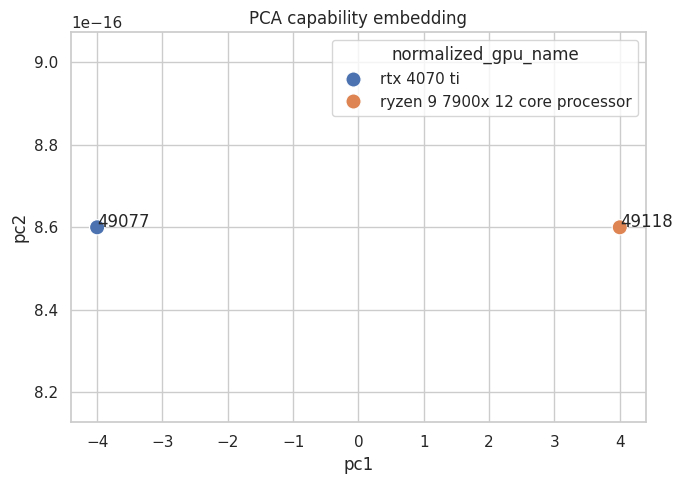

In [3]:
if embedding.shape[1] == 2:
    plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=embedding_frame, x="pc1", y="pc2", hue="normalized_gpu_name", s=120
    )
    for _, row in embedding_frame.iterrows():
        plt.text(row["pc1"], row["pc2"], row["report_id"])
    plt.title("PCA capability embedding")
    plt.tight_layout()
    plt.show()

In [4]:
cluster_count = min(2, len(X))
kmeans = KMeans(n_clusters=cluster_count, n_init=10, random_state=7)
agglomerative = AgglomerativeClustering(n_clusters=cluster_count)
cluster_frame = ml_frame[["report_id", "normalized_gpu_name"]].copy()
cluster_frame["kmeans_cluster"] = kmeans.fit_predict(X)
cluster_frame["agglomerative_cluster"] = agglomerative.fit_predict(X)
display(cluster_frame)

,report_id,normalized_gpu_name,kmeans_cluster,agglomerative_cluster
0,49077,rtx 4070 ti,0,1
1,49118,ryzen 9 7900x 12 core processor,1,0


In [5]:
if len(X) < 8:
    print(
        "PyTorch and TensorFlow autoencoder variants are intentionally skipped: the current dataset is too small to justify learned unsupervised representations."
    )
else:
    print(
        "Dataset is large enough to add autoencoder-based variants in a later iteration."
    )

PyTorch and TensorFlow autoencoder variants are intentionally skipped: the current dataset is too small to justify learned unsupervised representations.
